In [1]:
#IMPORTS
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay)

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)
RANDOM_STATE = 42
TARGET_RECALL = 0.75   # at enrollment there is less information, so 0.85 would mean flagging ~60% of students
GAP_LIMIT = 0.05       # largest acceptable recall gap between groups

In [2]:
# LOAD THE DATASET
df = pd.read_csv("../data/data.csv", sep=";")
if df.shape[1] == 1:              # Kaggle version uses commas
    df = pd.read_csv("../data/data.csv")
df.columns = df.columns.str.strip()
print(df.shape)
df.head()

(4424, 37)


,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


In [3]:

print(df["Target"].value_counts())

Target
Graduate    2209
Dropout     1421
Enrolled     794
Name: count, dtype: int64


In [4]:
df["dropout"] = (df["Target"] == "Dropout").astype(int)
df["Gender name"] = df["Gender"].map({0: "Female", 1: "Male"})
df["Age band"] = pd.cut(df["Age at enrollment"], [0, 20, 24, 200],
                        labels=["20 or under", "21-24", "25 and over"]).astype(str)
print(df["dropout"].value_counts(normalize=True).round(3))
print(df.groupby("Gender name")["dropout"].mean().round(3))
print(df.groupby("Age band")["dropout"].mean().round(3))

dropout
0    0.679
1    0.321
Name: proportion, dtype: float64
Gender name
Female    0.251
Male      0.451
Name: dropout, dtype: float64
Age band
20 or under    0.212
21-24          0.337
25 and over    0.554
Name: dropout, dtype: float64


In [5]:
enrollment_features = [
    "Marital status", "Application mode", "Application order", "Course",
    "Daytime/evening attendance", "Previous qualification",
    "Previous qualification (grade)", "Mother's qualification",
    "Father's qualification", "Mother's occupation", "Father's occupation",
    "Admission grade", "Displaced", "Educational special needs", "Debtor",
    "Tuition fees up to date", "Scholarship holder", "Age at enrollment",
    "International", "Unemployment rate", "Inflation rate", "GDP",
]
# These columns are codes (e.g. Course 9254 = Tourism), not amounts, so they are one-hot encoded
categorical_cols = ["Marital status", "Application mode", "Course", "Previous qualification",
                    "Mother's qualification", "Father's qualification",
                    "Mother's occupation", "Father's occupation"]
numeric_cols = [f for f in enrollment_features if f not in categorical_cols]

X = df[enrollment_features]
y = df["dropout"]
gender = df["Gender name"]   # used only for fairness, not as a feature
age_band = df["Age band"]    # used only for fairness (age itself is a feature)

In [6]:
#TRAINING TESTING AND SPLITTING
X_train, X_test, y_train, y_test, g_train, g_test, a_train, a_test = train_test_split(
    X, y, gender, age_band, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

def make_model():
    prep = ColumnTransformer([("num", StandardScaler(), numeric_cols),
                              ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=10), categorical_cols)])
    return Pipeline([("prep", prep), ("model", LogisticRegression(max_iter=3000))])

print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (3539, 22)  Test: (885, 22)


In [7]:
#FAIRNESS CONSTRAINTS REWEIGHING
# Reweigh by gender x age band: age is where the biggest gap is (see the comparison at the end)
def reweighing_weights(y, group):
    w = np.zeros(len(y))
    for g in np.unique(group):
        for label in [0, 1]:
            mask = (group == g) & (y == label)
            expected = (group == g).mean() * (y == label).mean()
            observed = mask.mean()
            w[mask] = expected / observed
    return w

fair_group_train = (g_train + ", " + a_train).values
sample_weights = reweighing_weights(y_train.values, fair_group_train)
print(pd.DataFrame({"Group": fair_group_train, "dropout": y_train.values, "weight": sample_weights})
      .groupby(["Group", "dropout"])["weight"].first().round(3))


def threshold_for_recall(y_true, prob, target):
    """Highest cut-off that still catches at least `target` of the dropouts."""
    for t in np.arange(0.95, 0.04, -0.01):
        if recall_score(y_true, (prob >= t).astype(int)) >= target:
            return round(float(t), 2)
    return 0.05

Group                dropout
Female, 20 or under  0          0.825
                     1          1.808
Female, 21-24        0          0.954
                     1          1.113
Female, 25 and over  0          1.259
                     1          0.697
Male, 20 or under    0          0.996
                     1          1.008
Male, 21-24          0          1.108
                     1          0.829
Male, 25 and over    0          1.959
                     1          0.492
Name: weight, dtype: float64


In [8]:
#TRAIN THE MODEL
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
model = make_model()

# Decision threshold: chosen on out-of-fold training predictions, never on the test set
oof_prob = cross_val_predict(model, X_train, y_train, cv=cv, method="predict_proba",
                             params={"model__sample_weight": sample_weights})[:, 1]
THRESHOLD = threshold_for_recall(y_train.values, oof_prob, TARGET_RECALL)
print("Decision threshold:", THRESHOLD)

model.fit(X_train, y_train, model__sample_weight=sample_weights)
print("Model trained on", len(X_train), "students")

Decision threshold: 0.25
Model trained on 3539 students


Accuracy : 0.680
Precision: 0.501
Recall   : 0.761
F1-score : 0.604
ROC-AUC  : 0.796
Flagged  : 48.7% of students


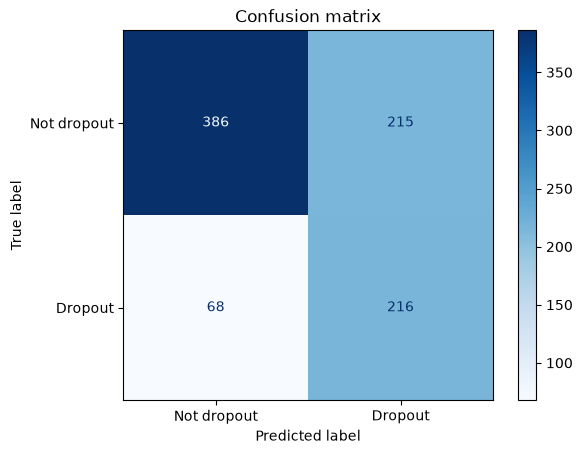

In [9]:
#OVERALL PERFORMANCE
y_prob = model.predict_proba(X_test)[:, 1]
y_pred = (y_prob >= THRESHOLD).astype(int)

print(f"Accuracy : {accuracy_score(y_test, y_pred):.3f}")
print(f"Precision: {precision_score(y_test, y_pred):.3f}")
print(f"Recall   : {recall_score(y_test, y_pred):.3f}")
print(f"F1-score : {f1_score(y_test, y_pred):.3f}")
print(f"ROC-AUC  : {roc_auc_score(y_test, y_prob):.3f}")
print(f"Flagged  : {y_pred.mean():.1%} of students")

ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred),
                       display_labels=["Not dropout", "Dropout"]).plot(cmap="Blues")
plt.title("Confusion matrix"); plt.show()

In [10]:
#FAIRNESS CHECK BY GENDER AND AGE
def group_report(y_true, y_pred, group):
    rows = []
    for g in sorted(np.unique(group), key=str):
        m = (group == g)
        tn, fp, fn, tp = confusion_matrix(y_true[m], y_pred[m], labels=[0, 1]).ravel()
        rows.append({"Group": g, "Students": int(m.sum()), "Dropouts": int(tp + fn),
                     "Selection rate": y_pred[m].mean(),
                     "Recall (TPR)": tp / (tp + fn),
                     "False positive rate": fp / (fp + tn),
                     "Precision": tp / (tp + fp) if (tp + fp) else 0,
                     "Accuracy": (tp + tn) / m.sum()})
    return pd.DataFrame(rows).set_index("Group").round(3)


def recall_gap(y_true, y_pred, group):
    r = [y_pred[(group == g) & (y_true == 1)].mean() for g in np.unique(group)]
    return max(r) - min(r)


def bootstrap_gap(y_true, y_pred, group, n=2000, seed=RANDOM_STATE):
    """95% interval for the recall gap: the test set is small, so gaps of a few points can be noise."""
    rng = np.random.default_rng(seed)
    gaps = []
    for _ in range(n):
        i = rng.integers(0, len(y_true), len(y_true))
        gaps.append(recall_gap(y_true[i], y_pred[i], group[i]))
    return np.percentile(gaps, [2.5, 97.5]).round(3)


reports = {}
for name, grp in [("Gender", g_test.values), ("Age band", a_test.values)]:
    reports[name] = group_report(y_test.values, y_pred, grp)
    lo, hi = bootstrap_gap(y_test.values, y_pred, grp)
    print(f"--- {name} ---")
    print(reports[name])
    print(f"Demographic parity difference: {reports[name]['Selection rate'].max() - reports[name]['Selection rate'].min():.3f}")
    print(f"Equal opportunity difference : {recall_gap(y_test.values, y_pred, grp):.3f}  (95% interval {lo} to {hi})\n")

--- Gender ---
        Students  Dropouts  Selection rate  Recall (TPR)  False positive rate  Precision  Accuracy
Group                                                                                             
Female       564       138           0.441         0.754                 0.34      0.418     0.683
Male         321       146           0.567         0.767                 0.40      0.615     0.676
Demographic parity difference: 0.126
Equal opportunity difference : 0.014  (95% interval 0.002 to 0.124)

--- Age band ---
             Students  Dropouts  Selection rate  Recall (TPR)  False positive rate  Precision  Accuracy
Group                                                                                                  
20 or under       513       102           0.423         0.725                0.348      0.341     0.667
21-24             139        51           0.482         0.765                0.318      0.582     0.712
25 and over       233       131           0.631   

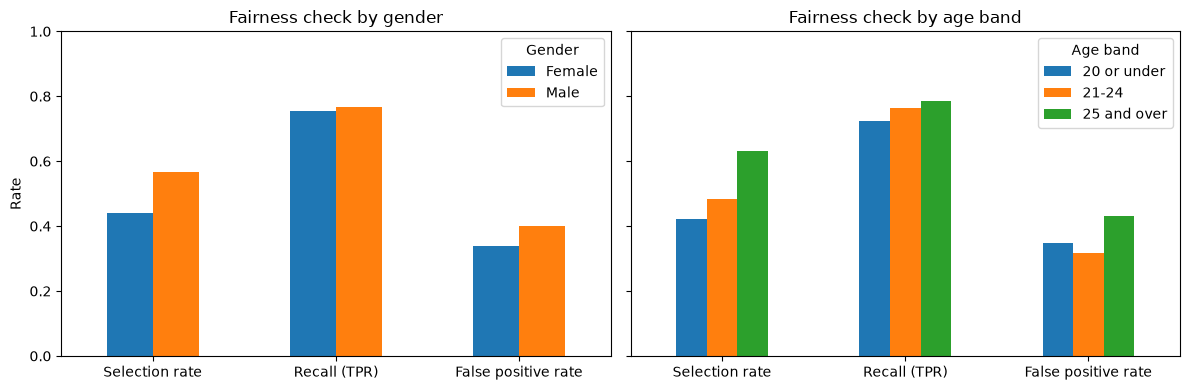

In [11]:
#FAIRNESS CHART
fig, ax = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for a, name in zip(ax, ["Gender", "Age band"]):
    reports[name][["Selection rate", "Recall (TPR)", "False positive rate"]].T.plot(kind="bar", rot=0, ax=a)
    a.set_title(f"Fairness check by {name.lower()}"); a.set_ylim(0, 1); a.legend(title=name)
ax[0].set_ylabel("Rate")
plt.tight_layout(); plt.show()

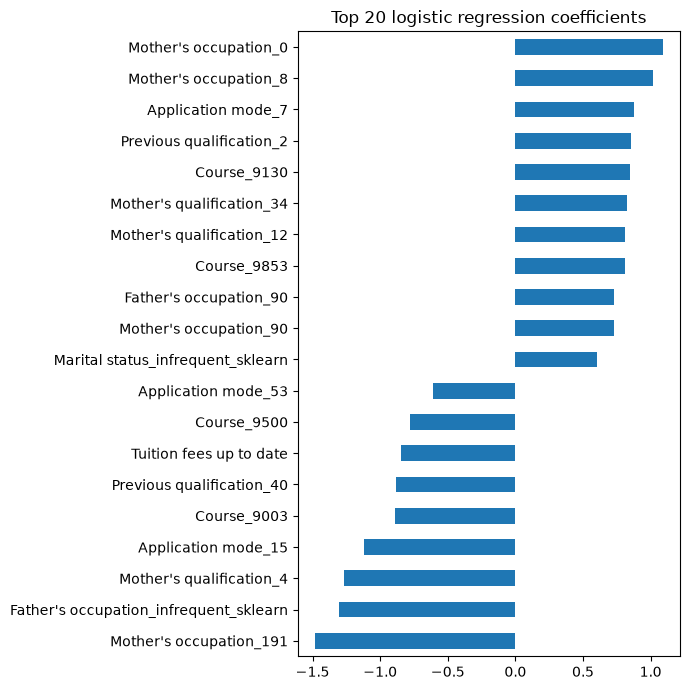

In [12]:
#WHICH FACTORS DRIVE DROPOUT RISK
names = model.named_steps["prep"].get_feature_names_out()
names = [n.split("__", 1)[1] for n in names]
coef = pd.Series(model.named_steps["model"].coef_[0], index=names)
top = coef.reindex(coef.abs().sort_values(ascending=False).index).head(20).sort_values()
top.plot(kind="barh", figsize=(7, 7))
plt.title("Top 20 logistic regression coefficients"); plt.tight_layout(); plt.show()

In [13]:
#EARLY WARNING OUTPUT RISK LEVELS
def risk_level(p, t=THRESHOLD):
    if p >= max(0.7, t + 0.2): return "High"
    if p >= t: return "Medium"
    return "Low"

alerts = pd.DataFrame({"Gender": g_test.values, "Age band": a_test.values,
                       "Dropout probability": y_prob.round(3),
                       "Risk level": [risk_level(p) for p in y_prob],
                       "Actual": y_test.map({0: "Not dropout", 1: "Dropout"}).values})
print(alerts["Risk level"].value_counts())
print(pd.crosstab(alerts["Risk level"], alerts["Actual"]))
alerts.sort_values("Dropout probability", ascending=False).head(10)

Risk level
Low       454
Medium    311
High      120
Name: count, dtype: int64
Actual      Dropout  Not dropout
Risk level                      
High            107           13
Low              68          386
Medium          109          202


,Gender,Age band,Dropout probability,Risk level,Actual
604,Female,21-24,0.997,High,Dropout
90,Male,25 and over,0.994,High,Dropout
52,Female,25 and over,0.993,High,Dropout
238,Female,25 and over,0.986,High,Dropout
288,Male,25 and over,0.977,High,Dropout
602,Female,25 and over,0.977,High,Dropout
252,Male,25 and over,0.974,High,Dropout
568,Male,20 or under,0.972,High,Dropout
514,Male,25 and over,0.972,High,Dropout
808,Female,25 and over,0.970,High,Not dropout


In [14]:
#COMPARISON: WHICH GROUPS TO REWEIGH
rows = {}
for name, grp in [("No reweighing", None), ("Reweigh by gender", g_train.values),
                  ("Reweigh by gender x age (used)", fair_group_train)]:
    params = {} if grp is None else {"model__sample_weight": reweighing_weights(y_train.values, grp)}
    oof = cross_val_predict(make_model(), X_train, y_train, cv=cv, method="predict_proba", params=params)[:, 1]
    t = threshold_for_recall(y_train.values, oof, TARGET_RECALL)
    m = make_model().fit(X_train, y_train, **params)
    p = m.predict_proba(X_test)[:, 1]
    pred = (p >= t).astype(int)
    rows[name] = {"ROC-AUC": roc_auc_score(y_test, p), "Recall": recall_score(y_test, pred),
                  "Precision": precision_score(y_test, pred), "Flagged": pred.mean(),
                  "Gender recall gap": recall_gap(y_test.values, pred, g_test.values),
                  "Age recall gap": recall_gap(y_test.values, pred, a_test.values)}
print(pd.DataFrame(rows).T.round(3))
print("\nReweighing by gender alone leaves a large age gap; adding age closes it, at some cost in ROC-AUC and precision.")

                                ROC-AUC  Recall  Precision  Flagged  Gender recall gap  Age recall gap
No reweighing                     0.834   0.792      0.556    0.458              0.033           0.294
Reweigh by gender                 0.826   0.764      0.549    0.446              0.006           0.293
Reweigh by gender x age (used)    0.796   0.761      0.501    0.487              0.014           0.061

Reweighing by gender alone leaves a large age gap; adding age closes it, at some cost in ROC-AUC and precision.
